Importar datos :D

In [22]:
import pandas as pd
import openpyxl
import numpy as np
import missingno as msno
from functools import reduce
import seaborn as sns
import matplotlib.pyplot as plt

# configs para pandas
pd.set_option("display.max_rows", None)  # Show all rows
pd.set_option("display.max_columns", None)  # Show all columns
pd.set_option("display.width", 1000)

In [23]:
df_1 = pd.read_excel("datos_raw/Totalizadores Planta - 2021_2023.xlsx", sheet_name=None)
df_2 = pd.read_excel("datos_raw/Totalizadores Planta 2020_2022.xlsx", sheet_name=None)
df_3 = pd.read_excel("datos_raw/Totalizadores Planta 2022_2023.xlsx", sheet_name=None)


In [24]:
# cambiar el df_n para ver los otros excel
i = 0
for k in df_1.values():
    i+=1
    print()
    print(f" ------------ {i} ---------------\n")
    lista = k.groupby(k['DIA'].dt.to_period('D'))['DIA'].count()
    for dia, cantidad in lista.items():
        if cantidad != 25:
            print(dia, cantidad)


 ------------ 1 ---------------

2021-07-01 23
2021-07-13 23
2021-09-30 50
2021-10-09 24
2021-11-01 23
2021-11-30 50
2022-02-28 100
2022-03-02 24
2022-03-05 24
2022-04-30 50
2022-06-30 51
2022-09-30 50
2022-11-30 50
2023-01-17 16
2023-02-28 99
2023-03-06 9

 ------------ 2 ---------------

2021-07-01 23
2021-07-13 23
2021-09-30 50
2021-10-09 24
2021-11-01 23
2021-11-30 50
2022-02-28 100
2022-03-02 24
2022-03-05 24
2022-04-30 50
2022-06-30 51
2022-09-30 50
2022-11-30 50
2023-01-17 16
2023-02-28 99
2023-03-06 9

 ------------ 3 ---------------

2021-07-01 23
2021-07-13 23
2021-09-30 50
2021-10-09 24
2021-11-01 23
2021-11-30 50
2022-02-28 100
2022-03-02 24
2022-03-05 24
2022-04-30 50
2022-06-30 51
2022-09-30 50
2022-11-30 50
2023-01-17 16
2023-02-28 99
2023-03-06 9

 ------------ 4 ---------------

2021-07-01 23
2021-07-13 23
2021-09-30 50
2021-10-09 24
2021-11-01 23
2021-11-30 50
2022-02-28 100
2022-03-02 24
2022-03-05 24
2022-04-30 50
2022-06-30 51
2022-09-30 50
2022-11-30 50
2023-01-1

In [25]:
archivos = {
    "2021_2023": df_1,
    "2020_2022": df_2,
    "2022_2023": df_3,
}

COL_FECHA = "fecha"

def limpiar(df):
    df = df.copy()
    df.columns = df.columns.astype(str).str.strip().str.lower()

    dia = pd.to_datetime(df["dia"], errors="coerce").dt.normalize()

    h = df["hora"]
    if pd.api.types.is_datetime64_any_dtype(h):
        h = h.dt.strftime("%H:%M:%S")
    hora = pd.to_timedelta(h.astype(str), errors="coerce")

    # quedarse solo con los cierres de día (23:30 en adelante)
    es_cierre = (hora >= pd.Timedelta(hours=23, minutes=30)) & (hora < pd.Timedelta(days=1))
    df = df[es_cierre].copy()

    # fijar la marca de tiempo en 23:59:00 exactos
    df[COL_FECHA] = dia[es_cierre]     #.dt.date
    df = df.drop(columns=["dia", "hora"])
    df = df.dropna(subset=[COL_FECHA])
    df["_n"] = df.groupby(COL_FECHA).cumcount()   # orden de aparición de cada fecha repetida
    return df

def elegir_mas_similar(df):
    """Para cada fecha repetida calcula la desviación de cada fila contra el día anterior
    y el siguiente, se queda con la de menor desviación y borra las otras. Quita `_n`."""
    df = df.sort_values([COL_FECHA, "_n"]).reset_index(drop=True)
    num = df.select_dtypes("number").columns.drop(["_n", "id"], errors="ignore")
    escala = df[num].std().replace(0, np.nan)

    # valor típico de cada día; se desplaza para obtener el día anterior y el siguiente
    por_dia = df.groupby(COL_FECHA)[num].median()
    anterior = por_dia.shift(1).loc[df[COL_FECHA]].set_axis(df.index)
    siguiente = por_dia.shift(-1).loc[df[COL_FECHA]].set_axis(df.index)

    # desviación de cada fila (normalizada por columna, ignorando NaN)
    desv_ant = ((df[num] - anterior).abs() / escala).mean(axis=1, skipna=True)
    desv_sig = ((df[num] - siguiente).abs() / escala).mean(axis=1, skipna=True)
    desv = pd.concat([desv_ant, desv_sig], axis=1).mean(axis=1, skipna=True).fillna(np.inf)

    # por fecha, quedarse con la fila de menor desviación
    elegidas = desv.groupby(df[COL_FECHA]).idxmin()
    return df.loc[elegidas].drop(columns="_n").reset_index(drop=True)

def unir_hojas(dic):
    partes = []
    for hoja, df in dic.items():
        df = limpiar(df)
        n_antes = len(df)
        df = elegir_mas_similar(df).set_index(COL_FECHA)   # colapsa fechas repetidas dentro de la hoja
        if len(df) < n_antes:
            print(f"'{hoja}': {n_antes - len(df)} filas colapsadas por fecha repetida")
        partes.append(df)
    return reduce(lambda a, b: a.combine_first(b), partes)

def borrar_columnas_vacias(df, min = 1100):
    empty_columns = []
    for col in df.columns:
        a =df[col].isnull().sum() >= min
        if a:
            empty_columns.append(col)
            print(f"{col}")
    df.drop(columns=empty_columns, inplace=True)


tot_1 = unir_hojas(df_1)
tot_2 = unir_hojas(df_2)
tot_3 = unir_hojas(df_3)

df_total = (
    reduce(lambda a, b: a.combine_first(b), [tot_1, tot_2, tot_3])
    .sort_index()
    .reset_index()
)

print(df_total.shape)
print(df_total[COL_FECHA].is_unique)   # debe dar True

borrar_columnas_vacias(df_total)

# AGREGAR LA VARIABLE OBJETIVO
df_total["frio_mañana (kw)"] = df_total["frio (kw)"].shift(-1)


'Consolidado KPI': 12 filas colapsadas por fecha repetida
'Consolidado Produccion': 12 filas colapsadas por fecha repetida
'Totalizadores Produccion': 12 filas colapsadas por fecha repetida
'Consolidado EE': 12 filas colapsadas por fecha repetida
'Totalizadores Energia': 12 filas colapsadas por fecha repetida
'Consolidado Agua': 12 filas colapsadas por fecha repetida
'Totalizadores Agua': 12 filas colapsadas por fecha repetida
'Consolidado GasVapor': 12 filas colapsadas por fecha repetida
'Totalizadores Gas y Vapor': 12 filas colapsadas por fecha repetida
'Consolidado Aire': 12 filas colapsadas por fecha repetida
'Totalizadores Aire': 12 filas colapsadas por fecha repetida
'Totalizadores CO2': 13 filas colapsadas por fecha repetida
'Totalizadores Efluentes': 12 filas colapsadas por fecha repetida
'Totalizadores Glicol': 12 filas colapsadas por fecha repetida
'Seguimiento Dia': 12 filas colapsadas por fecha repetida
'Auxiliar': 12 filas colapsadas por fecha repetida
'Consolidado KPI': 1

C:\Users\carra\AppData\Local\Temp\ipykernel_37136\2613958406.py:80: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .reset_index()
C:\Users\carra\AppData\Local\Temp\ipykernel_37136\2613958406.py:89: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_total["frio_mañana (kw)"] = df_total["frio (kw)"].shift(-1)


In [26]:
df_total[df_total.duplicated("fecha",keep=False)] \
    .sort_values("fecha")

,fecha,ee planta / hl,ee elaboracion / hl,ee bodega / hl,ee cocina / hl,ee envasado / hl,ee linea 2 / hl,ee linea 3 / hl,ee linea 4 / hl,ee servicios / hl,ee sala maq / hl,ee frio / hl,ee aire / hl,ee co2 / hl,ee caldera / hl,ee eflu / hl,ee agua / hl,ee resto serv / hl,ee resto planta / hl,agua planta / hl,agua elab / hl,agua bodega / hl,agua cocina / hl,agua envas / hl,agua linea 2/hl,agua linea 3/hl,agua linea 4/hl,agua linea 5/hl,agua servicios/hl,agua planta de agua/hl,produccion agua / hl,et planta / hl,et elab/hl,et bodega/hl,et cocina/hl,et envasado/hl,et linea 2/hl,et linea 3/hl,et linea 4/hl,et linea 5/hl,et servicios / hl,aire planta / hl,aire elaboracion / hl,aire cocina / hl,aire bodega / hl,aire envasado / hl,aire l2 / hl,aire l3 / hl,aire l4 / hl,aire l5 / hl,aire servicios / hl,aire expulsion / hl,co 2 / hl,co 2 filtro / hl,co 2 linea 3 / hl,co 2 linea 4 / hl,co 2 linea 2 / hl,agua lavadora l3 / hl,agua paste l3 / hl,meta ee planta,meta agua planta,meta et planta,meta aire planta,meta agua elab,meta agua bodega,meta agua cocina,meta agua envas,meta agua linea 2,meta agua linea 3,meta agua linea 4,meta agua linea 5,meta agua servicios,meta agua planta de agua,meta produccion agua,meta ee elaboracion,meta ee bodega,meta ee cocina,meta ee envasado,meta ee linea 2,meta ee linea 3,meta ee linea 4,meta ee linea 5,meta ee servicios,meta ee sala maq,meta ee frio,meta ee aire,meta ee co2,meta ee caldera,meta ee eflu,meta ee agua,meta ee resto serv,meta ee resto planta,meta et elab,meta et bodega,meta et cocina,meta et envasado,meta et linea 2,meta et linea 3,meta et linea 4,meta et linea 5,meta et servicios,meta aire elaboracion,meta aire cocina,meta aire bodega,meta aire envasado,meta aire l2,meta aire l3,meta aire l4,meta aire l5,meta aire servicios,hl de mosto,hl cerveza cocina,hl producido bodega,hl cerveza filtrada,hl cerveza envasada,hl cerveza l2,hl cerveza l3,hl cerveza l4,hl cerveza l5,cocimientos diarios,hl de mosto copia,hl mosto budweiser,hl mosto tecate,hl mosto local,hl mosto heineken,hl mosto negra,hl mosto fuerte,hl mosto indio,hl mosto palermo,hl mosto bieckert,hl mosto malta,hl mosto amstel,hl mosto sol,hl mosto frost,hl mosto miller,hl mosto ipa,hl mosto apa,hl mosto roja,hl mosto isenbeck,hl mosto golden,hl mosto amstel lager,hl mosto cautiva roja,hl mosto cautiva torrontes,hl mosto cautiva blend,hl mosto bieckert urbana,hl mosto bieckert bapa,hl mosto blue moon,hl reserva 7,hl reserva 8,hl cerveza sin diliuir a90,hl cerceza sin diluir a190,nivel silo bagazo norte (1),nivel silo bagazo sur (2),nivel tk restos lev,planta (kw),elaboracion (kw),bodega (kw),cocina (kw),envasado (kw),linea 2 (kw),linea 3 (kw),linea 4 (kw),servicios (kw),sala maq (kw),aire (kw),calderas (kw),efluentes (kw),frio (kw),pta agua / eflu (kw),prod agua (kw),resto serv (kw),restos planta (kw),kw gral planta,kw trafo 4,kw trafo 5,kw trafo 8,kw trafo 11,kw trafo 12,kw linea 2,kw mycom 1,kw mycom 2,kw mycom 3,kw mycom 4,kw mycom 5,kw mycom 6,kw mycom 7,kw trafo 9,kw trafo 10,kw cocina,kw molino,kw linea 3 y 4,kw linea 3,kw linea 4,kw servicio l2,kw planta de agua,kw llum/serv l2,kw casona,kw laboratorio,kw admininistracion,kw pta agua/log,kw bba glicol sala maq,kw comp kaeser,kw iluminacion l3,kw iluminacion l4,kw ilum dep l3/l4,kw cond 5. 6 y 9,kw cond 7. 8 y 11,kw cond 11. 12 y 13,kw bba glicol bod,kw co2,kw secador kaeser,kw caldera 3,kw caldera 4,kw filtr carbon,kw atlas 3,kw toma agua,kw enfr agua cocina,kw enfluentes coc,kw enfluente efl,kw enfluentes hidr,kw obrador contratistas,kw compresores aire,kw linea barriles,agua planta (hl),agua elaboracion (hl),agua bodega (hl),agua cocina (hl),agua dilucion (hl),agua envasado (hl),agua servicios (hl),planta de agua (hl),produccion (hl),red l1 y l2,fc l1 y l2,fc lavadora l2,red l3,fc lavadora l3,red paste l4,fc barriles,agua paste l3,agua lavadora l3,agua cond evaporativos,agua calderas,agua efluentes,agua co2,red paste l1,fc linea 3,rinser,red barriles,red bodega,fc cip bodega,fc c

<Axes: >

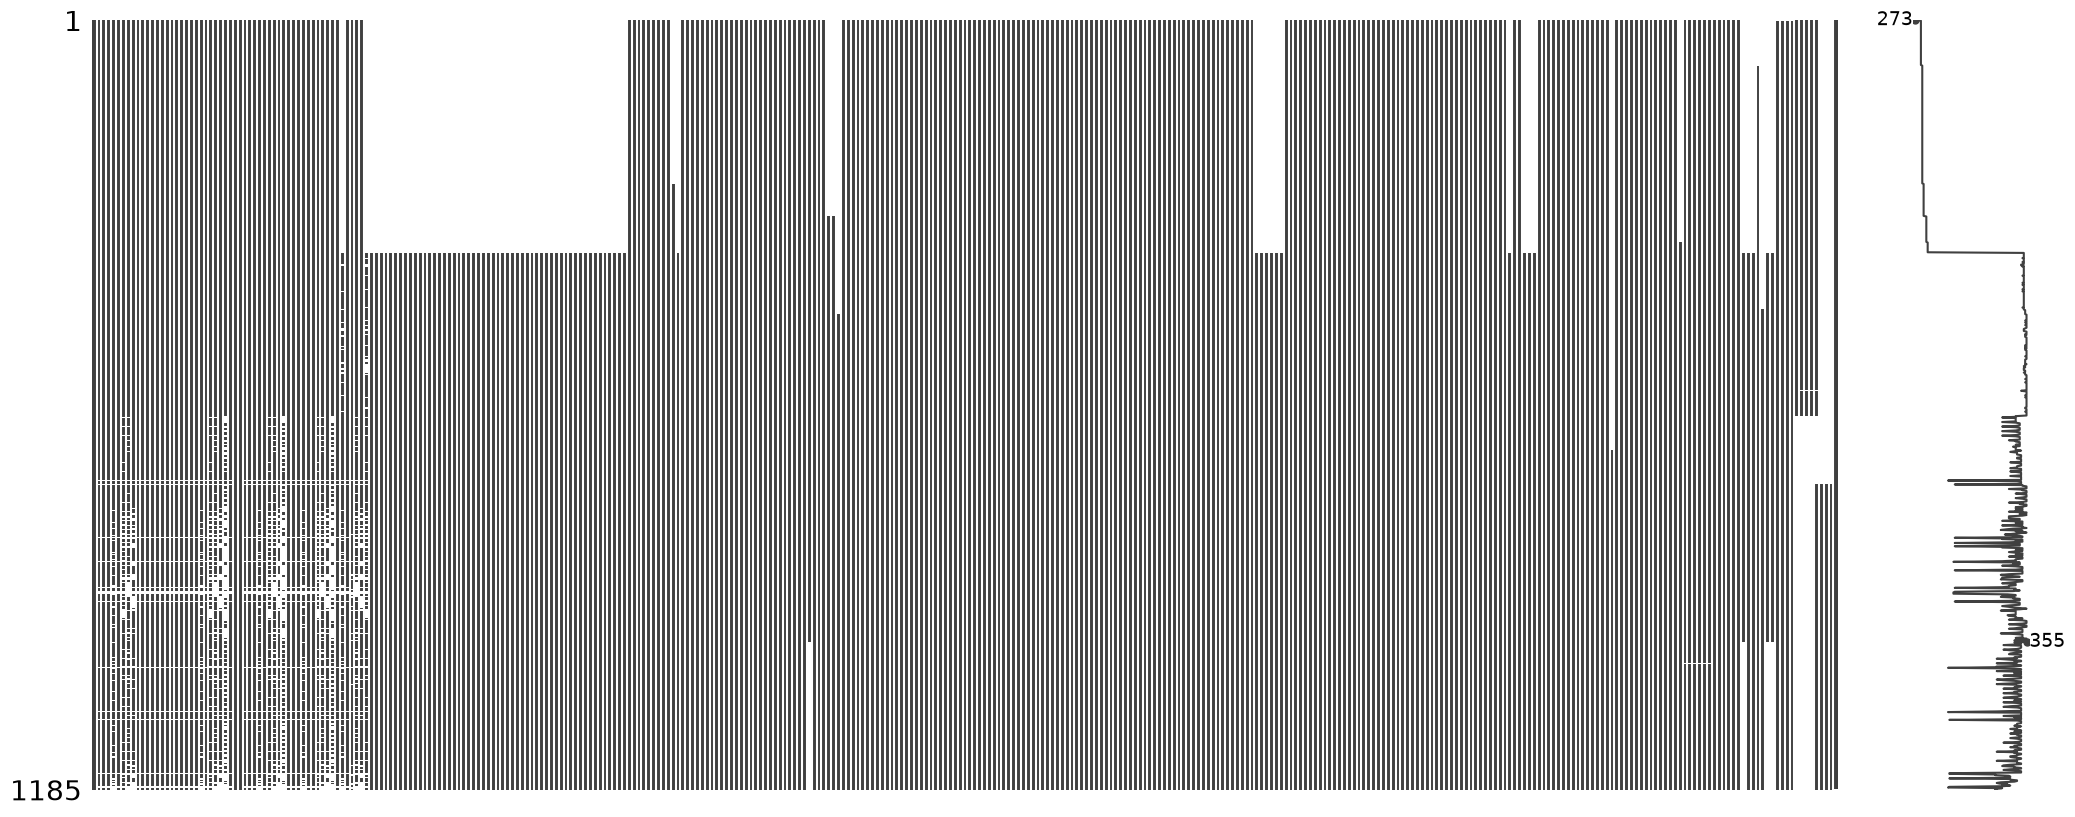

In [214]:
msno.matrix(df_total.sort_values("fecha"))

In [27]:
df_total.head()

,fecha,ee planta / hl,ee elaboracion / hl,ee bodega / hl,ee cocina / hl,ee envasado / hl,ee linea 2 / hl,ee linea 3 / hl,ee linea 4 / hl,ee servicios / hl,ee sala maq / hl,ee frio / hl,ee aire / hl,ee co2 / hl,ee caldera / hl,ee eflu / hl,ee agua / hl,ee resto serv / hl,ee resto planta / hl,agua planta / hl,agua elab / hl,agua bodega / hl,agua cocina / hl,agua envas / hl,agua linea 2/hl,agua linea 3/hl,agua linea 4/hl,agua linea 5/hl,agua servicios/hl,agua planta de agua/hl,produccion agua / hl,et planta / hl,et elab/hl,et bodega/hl,et cocina/hl,et envasado/hl,et linea 2/hl,et linea 3/hl,et linea 4/hl,et linea 5/hl,et servicios / hl,aire planta / hl,aire elaboracion / hl,aire cocina / hl,aire bodega / hl,aire envasado / hl,aire l2 / hl,aire l3 / hl,aire l4 / hl,aire l5 / hl,aire servicios / hl,aire expulsion / hl,co 2 / hl,co 2 filtro / hl,co 2 linea 3 / hl,co 2 linea 4 / hl,co 2 linea 2 / hl,agua lavadora l3 / hl,agua paste l3 / hl,meta ee planta,meta agua planta,meta et planta,meta aire planta,meta agua elab,meta agua bodega,meta agua cocina,meta agua envas,meta agua linea 2,meta agua linea 3,meta agua linea 4,meta agua linea 5,meta agua servicios,meta agua planta de agua,meta produccion agua,meta ee elaboracion,meta ee bodega,meta ee cocina,meta ee envasado,meta ee linea 2,meta ee linea 3,meta ee linea 4,meta ee linea 5,meta ee servicios,meta ee sala maq,meta ee frio,meta ee aire,meta ee co2,meta ee caldera,meta ee eflu,meta ee agua,meta ee resto serv,meta ee resto planta,meta et elab,meta et bodega,meta et cocina,meta et envasado,meta et linea 2,meta et linea 3,meta et linea 4,meta et linea 5,meta et servicios,meta aire elaboracion,meta aire cocina,meta aire bodega,meta aire envasado,meta aire l2,meta aire l3,meta aire l4,meta aire l5,meta aire servicios,hl de mosto,hl cerveza cocina,hl producido bodega,hl cerveza filtrada,hl cerveza envasada,hl cerveza l2,hl cerveza l3,hl cerveza l4,hl cerveza l5,cocimientos diarios,hl de mosto copia,hl mosto budweiser,hl mosto tecate,hl mosto local,hl mosto heineken,hl mosto negra,hl mosto fuerte,hl mosto indio,hl mosto palermo,hl mosto bieckert,hl mosto malta,hl mosto amstel,hl mosto sol,hl mosto frost,hl mosto miller,hl mosto ipa,hl mosto apa,hl mosto roja,hl mosto isenbeck,hl mosto golden,hl mosto amstel lager,hl mosto cautiva roja,hl mosto cautiva torrontes,hl mosto cautiva blend,hl mosto bieckert urbana,hl mosto bieckert bapa,hl mosto blue moon,hl reserva 7,hl reserva 8,hl cerveza sin diliuir a90,hl cerceza sin diluir a190,nivel silo bagazo norte (1),nivel silo bagazo sur (2),nivel tk restos lev,planta (kw),elaboracion (kw),bodega (kw),cocina (kw),envasado (kw),linea 2 (kw),linea 3 (kw),linea 4 (kw),servicios (kw),sala maq (kw),aire (kw),calderas (kw),efluentes (kw),frio (kw),pta agua / eflu (kw),prod agua (kw),resto serv (kw),restos planta (kw),kw gral planta,kw trafo 4,kw trafo 5,kw trafo 8,kw trafo 11,kw trafo 12,kw linea 2,kw mycom 1,kw mycom 2,kw mycom 3,kw mycom 4,kw mycom 5,kw mycom 6,kw mycom 7,kw trafo 9,kw trafo 10,kw cocina,kw molino,kw linea 3 y 4,kw linea 3,kw linea 4,kw servicio l2,kw planta de agua,kw llum/serv l2,kw casona,kw laboratorio,kw admininistracion,kw pta agua/log,kw bba glicol sala maq,kw comp kaeser,kw iluminacion l3,kw iluminacion l4,kw ilum dep l3/l4,kw cond 5. 6 y 9,kw cond 7. 8 y 11,kw cond 11. 12 y 13,kw bba glicol bod,kw co2,kw secador kaeser,kw caldera 3,kw caldera 4,kw filtr carbon,kw atlas 3,kw toma agua,kw enfr agua cocina,kw enfluentes coc,kw enfluente efl,kw enfluentes hidr,kw obrador contratistas,kw compresores aire,kw linea barriles,agua planta (hl),agua elaboracion (hl),agua bodega (hl),agua cocina (hl),agua dilucion (hl),agua envasado (hl),agua servicios (hl),planta de agua (hl),produccion (hl),red l1 y l2,fc l1 y l2,fc lavadora l2,red l3,fc lavadora l3,red paste l4,fc barriles,agua paste l3,agua lavadora l3,agua cond evaporativos,agua calderas,agua efluentes,agua co2,red paste l1,fc linea 3,rinser,red barriles,red bodega,fc cip bodega,fc c

In [28]:
df_total.to_excel("datos_clean/df_total.xlsx")

In [152]:
df_total["frio (kw)"]

0       14325.0
1       23954.0
2       28268.0
3       24246.0
4       29885.0
         ...   
1180     9481.0
1181    11587.0
1182    10123.0
1183    10360.0
1184    10568.0
Name: frio (kw), Length: 1185, dtype: float64

In [29]:
df_total["frio_mañana (kw)"]

0       23954.0
1       28268.0
2       24246.0
3       29885.0
4       24449.0
5       24435.0
6       33401.0
7       30921.0
8       27721.0
9       29046.0
10      35721.0
11      31017.0
12      34753.0
13      26648.0
14      27628.0
15      26595.0
16      30933.0
17      34890.0
18      33155.0
19      33436.0
20      38249.0
21      40886.0
22      33644.0
23      30355.0
24      36679.0
25      31448.0
26      33549.0
27      34214.0
28      31001.0
29      22781.0
30      30194.0
31      31674.0
32      26078.0
33      25260.0
34      27644.0
35      25407.0
36      30045.0
37      28152.0
38      26619.0
39      29181.0
40      30243.0
41      29964.0
42      31421.0
43      30191.0
44      28363.0
45      27017.0
46      25323.0
47      28135.0
48      27162.0
49      24973.0
50      24502.0
51      31548.0
52      35354.0
53      29323.0
54      37809.0
55      32562.0
56      29727.0
57      31514.0
58      27993.0
59      28731.0
60      31955.0
61      33024.0
62      

In [30]:
df_total["frio (kw)"]

0       14325.0
1       23954.0
2       28268.0
3       24246.0
4       29885.0
5       24449.0
6       24435.0
7       33401.0
8       30921.0
9       27721.0
10      29046.0
11      35721.0
12      31017.0
13      34753.0
14      26648.0
15      27628.0
16      26595.0
17      30933.0
18      34890.0
19      33155.0
20      33436.0
21      38249.0
22      40886.0
23      33644.0
24      30355.0
25      36679.0
26      31448.0
27      33549.0
28      34214.0
29      31001.0
30      22781.0
31      30194.0
32      31674.0
33      26078.0
34      25260.0
35      27644.0
36      25407.0
37      30045.0
38      28152.0
39      26619.0
40      29181.0
41      30243.0
42      29964.0
43      31421.0
44      30191.0
45      28363.0
46      27017.0
47      25323.0
48      28135.0
49      27162.0
50      24973.0
51      24502.0
52      31548.0
53      35354.0
54      29323.0
55      37809.0
56      32562.0
57      29727.0
58      31514.0
59      27993.0
60      28731.0
61      31955.0
62      

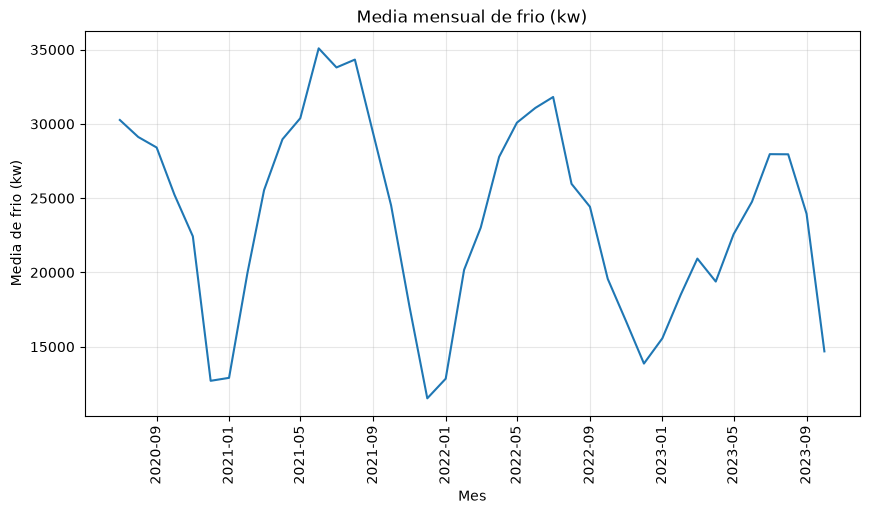

In [31]:

# Media mensual de frio (kw)
media_mensual = (
    df_total
    .groupby(df_total['fecha'].dt.to_period('M'))["frio (kw)"]
    .mean()
)

# Period no se puede graficar directo en matplotlib -> lo paso a Timestamp
x = media_mensual.index.to_timestamp()
y = media_mensual.values

plt.figure(figsize=(10, 5))
plt.plot(x, y)
plt.xlabel("Mes")
plt.ylabel("Media de frio (kw)")
plt.title("Media mensual de frio (kw)")
plt.grid(alpha=0.3)
plt.xticks(rotation=90)
plt.show()

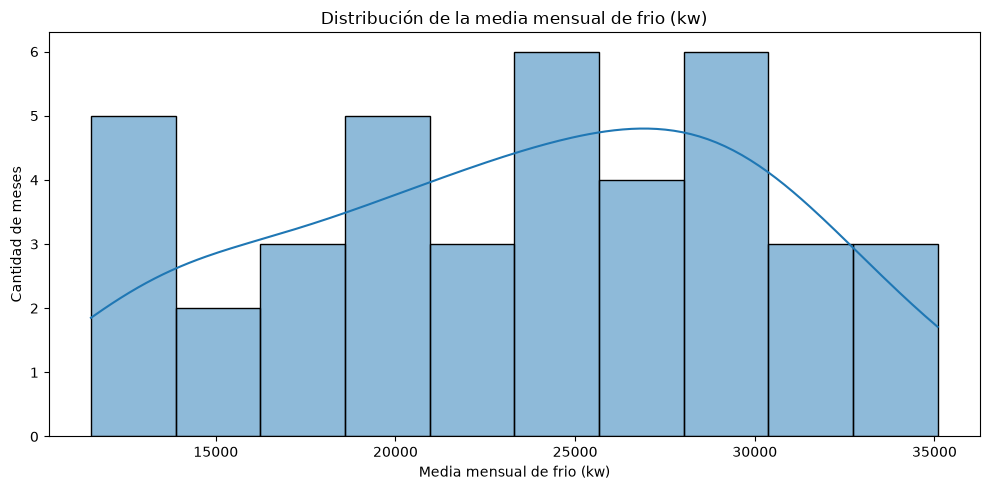

In [32]:


media_mensual = (
    df_total
    .groupby(df_total['fecha'].dt.to_period('M'))["frio (kw)"]
    .mean()
)

plt.figure(figsize=(10, 5))
sns.histplot(media_mensual, bins=10, kde=True)
plt.xlabel("Media mensual de frio (kw)")
plt.ylabel("Cantidad de meses")
plt.title("Distribución de la media mensual de frio (kw)")
plt.tight_layout()
plt.show()

In [33]:
excluir = ["id"] + [c for c in df_total.columns if c.endswith(("_sin", "_cos"))]
num = df_total.select_dtypes("number").columns.difference(excluir)

desc = df_total[num].describe().T
variabilidad = pd.DataFrame({
    "n_datos":  desc["count"],
    "% nulos":  df_total[num].isna().mean() * 100,
    "media":    desc["mean"],
    "desv_std": desc["std"],
    "cv":       desc["std"] / desc["mean"].abs(),          # coeficiente de variación
    "min":      desc["min"],
    "max":      desc["max"],
    "iqr":      desc["75%"] - desc["25%"],
}).round(3)
variabilidad = variabilidad.sort_values("cv", ascending=False)
variabilidad

,n_datos,% nulos,media,desv_std,cv,min,max,iqr
kw filtr carbon,1185.0,0.000,-53.157,14379.882,270.517,-294331.000,196644.000,137.000
restos planta (kw),1185.0,0.000,2101.950,147687.383,70.262,-4492792.320,2368897.100,2562.290
ee resto planta / hl,1164.0,1.772,0.370,19.262,52.101,-587.600,283.151,0.344
prod agua (kw),1185.0,0.000,412.470,14380.241,34.864,-293679.000,197630.000,518.000
totalizador bba gas,1185.0,0.000,0.257,8.860,34.424,0.000,305.000,0.000
hl mosto bieckert bapa,1185.0,0.000,2.354,60.508,25.699,0.000,1869.000,0.000
hl mosto blue moon,1185.0,0.000,2.356,57.330,24.332,0.000,1411.000,0.000
glicol paste l3,1185.0,0.000,0.017,0.376,22.702,0.000,11.730,0.000
tot vap paste l3 / hora,827.0,30.211,-1964.273,42390.742,21.581,-957112.500,552.500,229.550
kw linea 2,1185.0,0.000,6196.446,130527.394,21.065,0.000,4495238.000,3073.000


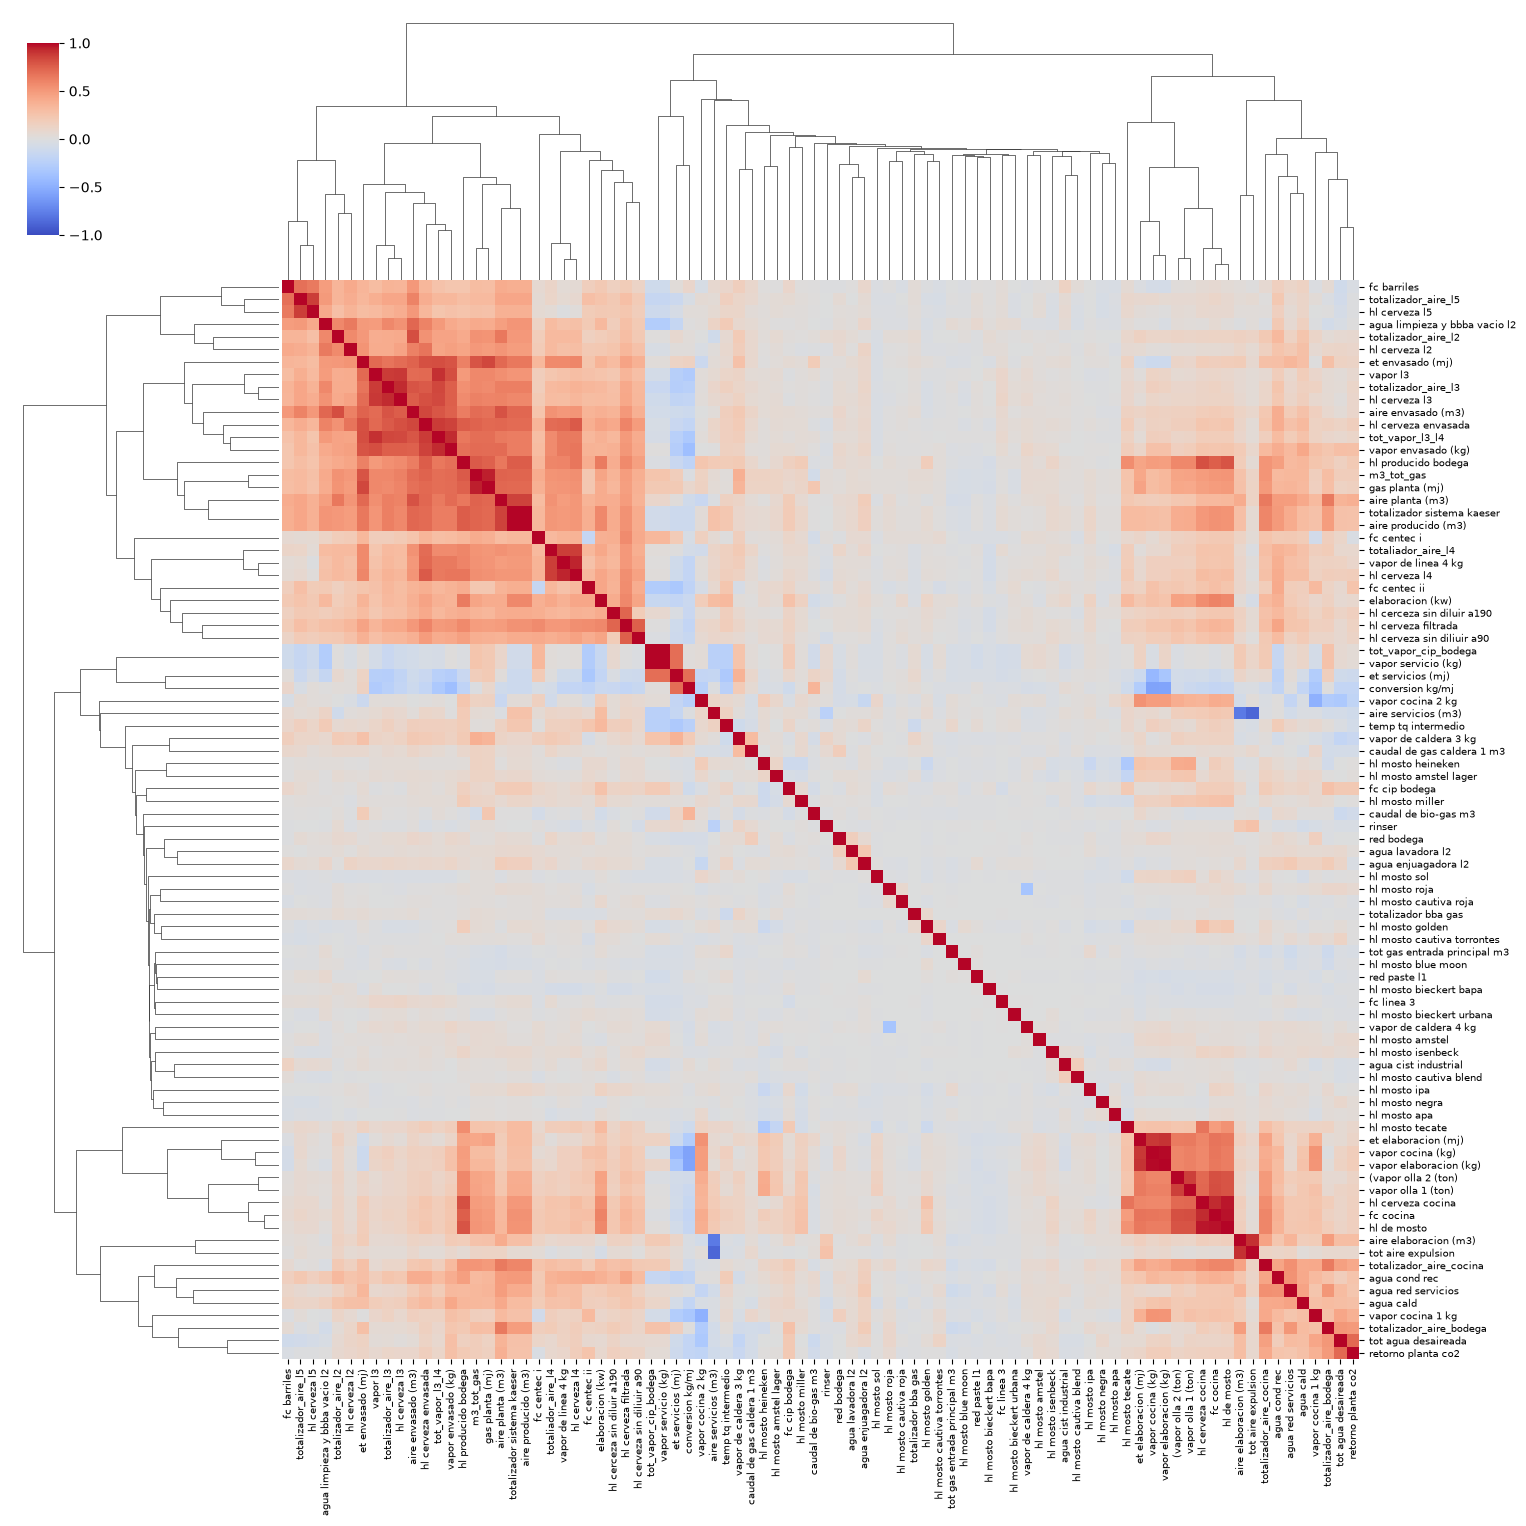

In [34]:
N = 100

num = df_total.select_dtypes("number").columns
sel = df_total[num].isna().mean().sort_values().head(N).index
sel = [c for c in sel if df_total[c].std() > 0]          # fuera columnas constantes

corr = df_total[sel].corr().fillna(0)                    # NaN -> sin correlación

g = sns.clustermap(
    corr, cmap="coolwarm", vmin=-1, vmax=1, center=0,
    figsize=(16, 16), xticklabels=True, yticklabels=True,
    cbar_pos=(0.02, 0.85, 0.02, 0.12),
)
g.ax_heatmap.tick_params(labelsize=7)
plt.show()
